In [1]:
import pandas as pd

df = pd.read_csv("../data/papers_screened.csv")
df["abstract"] = df["abstract"].fillna("")
df["text"] = df["title"] + ". " + df["abstract"]

print("Məqalə sayı:", len(df))
print("Abstraktsız:", (df["abstract"] == "").sum())

Məqalə sayı: 191
Abstraktsız: 38


In [2]:
from sentence_transformers import SentenceTransformer

model = SentenceTransformer("all-MiniLM-L6-v2")
embeddings = model.encode(df["text"].tolist(), show_progress_bar=True)

print("Ölçü:", embeddings.shape)

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Batches:   0%|          | 0/6 [00:00<?, ?it/s]

Ölçü: (191, 384)


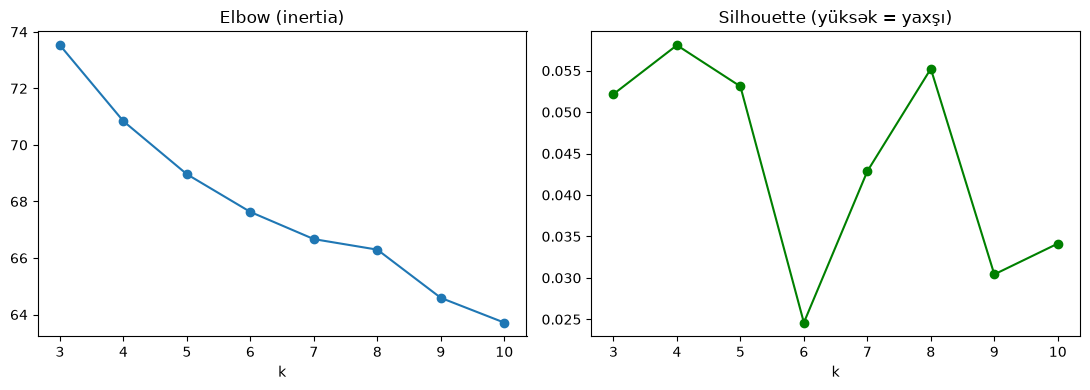

In [3]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import matplotlib.pyplot as plt

ks = range(3, 11)
inertias, sils = [], []

for k in ks:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = km.fit_predict(embeddings)
    inertias.append(km.inertia_)
    sils.append(silhouette_score(embeddings, labels))

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(ks, inertias, marker="o")
ax[0].set_title("Elbow (inertia)")
ax[0].set_xlabel("k")
ax[1].plot(ks, sils, marker="o", color="green")
ax[1].set_title("Silhouette (yüksək = yaxşı)")
ax[1].set_xlabel("k")
plt.tight_layout()
plt.show()

In [4]:
from sklearn.feature_extraction.text import TfidfVectorizer
import numpy as np

tfidf = TfidfVectorizer(stop_words="english", max_df=0.5, min_df=3, ngram_range=(1, 2))
X = tfidf.fit_transform(df["text"])
terms = np.array(tfidf.get_feature_names_out())

def describe_clusters(k):
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = km.fit_predict(embeddings)
    print(f"\n########## k = {k} ##########")
    for c in range(k):
        mask = labels == c
        mean_tfidf = np.asarray(X[mask].mean(axis=0)).ravel()
        top = terms[mean_tfidf.argsort()[::-1][:8]]
        print(f"\nCluster {c} ({mask.sum()} papers): {', '.join(top)}")
    return labels

labels_4 = describe_clusters(4)
labels_8 = describe_clusters(8)


########## k = 4 ##########

Cluster 0 (20 papers): films, alginate, edible, food, lignin, zein, films coatings, review

Cluster 1 (84 papers): starch, wax, oil, coated paper, barrier properties, water resistance, surface, materials

Cluster 2 (48 papers): chitosan, oil, chitosan coated, beeswax, food, biodegradable, papers, coated paper

Cluster 3 (39 papers): cellulose, cnf, nanocellulose, et, et al, barrier properties, al, mfc

########## k = 8 ##########

Cluster 0 (2 papers): wax, biodegradation, derived, days, bio, oil, beeswax, 50

Cluster 1 (45 papers): chitosan, oil, chitosan coated, beeswax, biodegradable, papers, coated paper, food

Cluster 2 (20 papers): alginate, films, food, edible, review, food packaging, antimicrobial, polysaccharides

Cluster 3 (35 papers): starch, food, food packaging, paper packaging, oil, coated paper, bio, barrier properties

Cluster 4 (33 papers): cellulose, cnf, nanocellulose, et al, et, al, mfc, barrier properties

Cluster 5 (23 papers): starch

In [5]:
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

custom_stop = list(ENGLISH_STOP_WORDS) + ["et", "al"]

tfidf = TfidfVectorizer(stop_words=custom_stop, max_df=0.5, min_df=3, ngram_range=(1, 2))
X = tfidf.fit_transform(df["text"])
terms = np.array(tfidf.get_feature_names_out())

labels_5 = describe_clusters(5)


########## k = 5 ##########

Cluster 0 (42 papers): wax, food, food packaging, bio, barrier properties, waxes, coated paper, materials

Cluster 1 (31 papers): cellulose, cnf, nanocellulose, mfc, high, nanofibrils, microfibrillated, surface

Cluster 2 (17 papers): films, alginate, edible, zein, food, lignin, films coatings, antimicrobial

Cluster 3 (47 papers): chitosan, oil, chitosan coated, beeswax, papers, biodegradable, coated paper, resistant

Cluster 4 (54 papers): starch, oil, coated paper, surface, zein, papers, water resistance, resistant


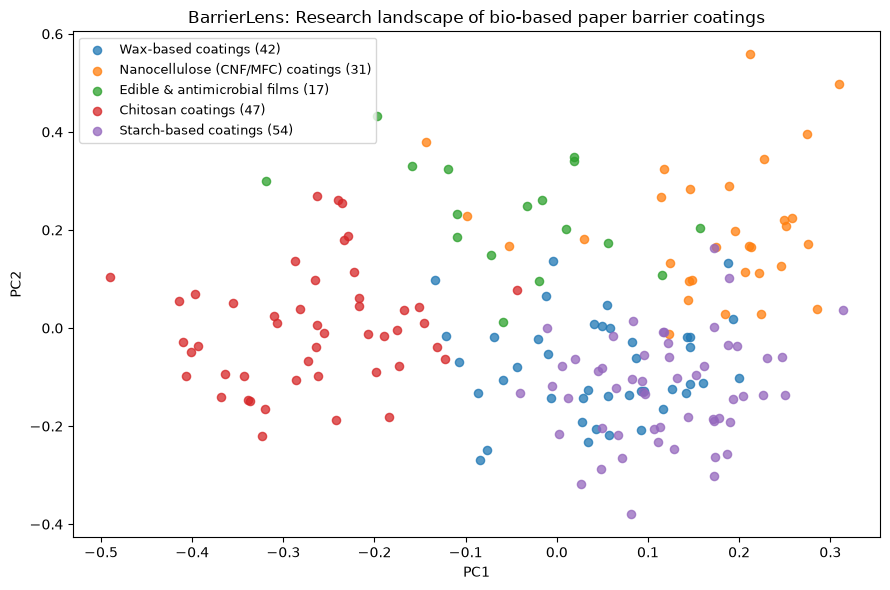

Explained variance (PC1 + PC2): 15.1 %


In [6]:
from sklearn.decomposition import PCA

CLUSTER_NAMES = {
    0: "Wax-based coatings",
    1: "Nanocellulose (CNF/MFC) coatings",
    2: "Edible & antimicrobial films",
    3: "Chitosan coatings",
    4: "Starch-based coatings",
}

df["cluster"] = labels_5
df["cluster_name"] = df["cluster"].map(CLUSTER_NAMES)

pca = PCA(n_components=2, random_state=42)
coords = pca.fit_transform(embeddings)
df["pc1"], df["pc2"] = coords[:, 0], coords[:, 1]

fig, ax = plt.subplots(figsize=(9, 6))
for c, name in CLUSTER_NAMES.items():
    sub = df[df["cluster"] == c]
    ax.scatter(sub["pc1"], sub["pc2"], label=f"{name} ({len(sub)})", s=35, alpha=0.75)
ax.set_title("BarrierLens: Research landscape of bio-based paper barrier coatings")
ax.set_xlabel("PC1")
ax.set_ylabel("PC2")
ax.legend(fontsize=9)
plt.tight_layout()
plt.savefig("../data/landscape_map.png", dpi=150)
plt.show()

print("Explained variance (PC1 + PC2):", round(pca.explained_variance_ratio_.sum() * 100, 1), "%")

In [7]:
df.drop(columns=["text"]).to_csv("../data/papers_clustered.csv", index=False, encoding="utf-8")
print("Saved: data/papers_clustered.csv")

Saved: data/papers_clustered.csv
